# 1 · The equations of motion of a rigid aircraft

The twelve-state rigid-body model, checked against motions with closed-form answers.
Lesson: [01](../docs/lessons/01-equations-of-motion.md) ·
Theory: [equations of motion](../docs/equations_of_motion.md).

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from flightdyn import plotting as P

P.use_style()
np.set_printoptions(precision=4, suppress=True)
sys.path.insert(0, "../validation")  # cited reference data and reference aircraft
from reference_aircraft import b747, b747_condition, navion, navion_condition
from scipy.integrate import solve_ivp
from flightdyn.aircraft import MassProperties
from flightdyn import equations_of_motion as eom
from flightdyn.rotations import dcm_body_from_ned

## Torque-free precession

An axisymmetric body ($I_{xx} = I_{yy} = I$, $I_{zz} = I_3$) spinning at r keeps r constant while
(p, q) rotates at $\Omega = (I_3 - I)r/I$.

precession rate 2.25 rad/s; max error in p: 6.5e-10


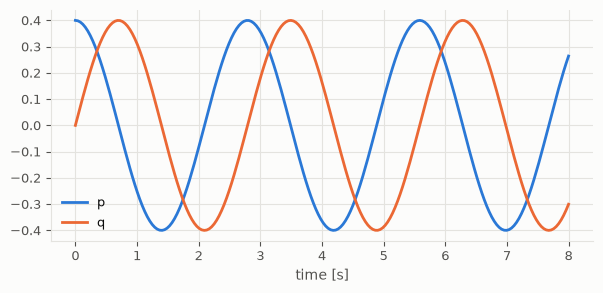

In [2]:
mp = MassProperties(mass=1.0, Ixx=2.0, Iyy=2.0, Izz=5.0)
x0 = np.zeros(12)
x0[eom.P], x0[eom.R] = 0.4, 1.5
t = np.linspace(0, 8, 200)
sol = solve_ivp(lambda _, x: eom.rigid_body_derivative(x, (0, 0, 0), (0, 0, 0), mp, 0.0),
                (0, 8), x0, t_eval=t, method="DOP853", rtol=1e-10, atol=1e-10)
omega = (5.0 - 2.0) * 1.5 / 2.0
print(f"precession rate {omega} rad/s; max error in p: "
      f"{np.abs(sol.y[eom.P] - 0.4 * np.cos(omega * t)).max():.1e}")
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t, sol.y[eom.P], label="p")
ax.plot(t, sol.y[eom.Q], label="q")
ax.set_xlabel("time [s]")
ax.legend();

## A tumbling body still falls along a parabola

Gravity alone acts on the centre of gravity, whatever the body does about it.

In [3]:
mp = MassProperties(mass=1200.0, Ixx=1400.0, Iyy=4000.0, Izz=4800.0, Ixz=250.0)
x0 = np.zeros(12)
x0[[0, 1, 2]] = (30.0, -4.0, 6.0)
x0[[3, 4, 5]] = (1.2, -0.7, 0.4)
x0[[6, 7, 8]] = (0.3, 0.2, -0.5)
v_ned = dcm_body_from_ned(0.3, 0.2, -0.5).T @ x0[:3]
t = np.linspace(0, 3, 13)
sol = solve_ivp(lambda _, x: eom.rigid_body_derivative(x, (0, 0, 0), (0, 0, 0), mp),
                (0, 3), x0, t_eval=t, method="DOP853", rtol=1e-11, atol=1e-11)
parabola = v_ned[2] * t + 0.5 * 9.80665 * t**2
print(f"largest departure from the parabola: {np.abs(sol.y[eom.ZD] - parabola).max():.1e} m")

largest departure from the parabola: 3.7e-10 m
